# SVD: a Tiny Example


In [86]:
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer

texts = [
    "bad",
    "nice name",
    "bad name name name",
    "nice"
]

X = CountVectorizer().fit_transform(texts).toarray()

pd.DataFrame(X, columns=CountVectorizer().fit(texts).get_feature_names_out(), index=texts)

,bad,name,nice
bad,1,0,0
nice name,0,1,1
bad name name name,1,3,0
nice,0,0,1


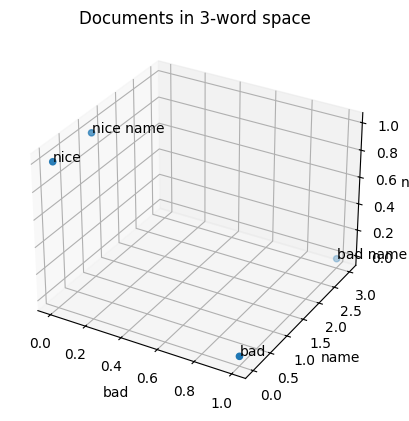

In [87]:
import matplotlib.pyplot as plt

fig = plt.figure()
ax = fig.add_subplot(111, projection="3d")

ax.scatter(X[:, 0], X[:, 1], X[:, 2])

for i, text in enumerate(texts):
    ax.text(X[i, 0], X[i, 1], X[i, 2], f"{text}")

ax.set_xlabel("bad")
ax.set_ylabel("name")
ax.set_zlabel("nice")
ax.set_title("Documents in 3-word space")
plt.show()

In [88]:
# Dot products: word similarities based on co-occurrence in documents
X.T @ X

array([[ 2,  3,  0],
       [ 3, 10,  1],
       [ 0,  1,  2]])

## Similarities (dot products) and correlations between word vectors

Look at the matrix $X^\top X$ in the previous code cell. The diagonal elements of this matrix are squared lengths of the word vectors. The word "name" occurs three times in the corpus, 2 times in the third document. Its square length is

$$
(0, 1, 2, 0) \cdot (0, 1, 2, 0) = 0^2 + 1^2 + 2^2 + 0^2 = 5
$$

The words "bad" and "name" occur together in the third document, so their dot product is

$$
(1, 0, 1, 0) \cdot (0, 1, 2, 0) = 0*1 + 1*0 + 2*1 + 0*0 = 2
$$

and they are more similar to each other than "bad" and "nice", which don't occur in the same document anywhere and have a zero dot product (are orthogonal to each other):

$$
(1, 0, 1, 0) \cdot (0, 1, 0, 1) = 1*0 + 0*1 + 1*0 + 0*1 = 0
$$

Note that $X^\top X$ is simply a matrix of dot products between every pair of word vectors. You are already familiar with the covariance matrix, a matrix with elements:

$$
\frac{1}{N} \sum_{k=1}^N (x_{ki} - \bar{x}_i)(x_{kj} - \bar{x}_j)
$$

In fact, centering every column of $X$ to zero mean and taking $X^\top X$ after that is equivalent to computing the covariance matrix.

In [89]:
X1 = (X - X.mean(axis=0))
X1

array([[ 0.5, -1. , -0.5],
       [-0.5,  0. ,  0.5],
       [ 0.5,  2. , -0.5],
       [-0.5, -1. ,  0.5]])

In [90]:
X1.T @ X1 / (X1.shape[0])

array([[ 0.25,  0.25, -0.25],
       [ 0.25,  1.5 , -0.25],
       [-0.25, -0.25,  0.25]])

In [91]:
np.cov(X, rowvar=False, ddof=0)

array([[ 0.25,  0.25, -0.25],
       [ 0.25,  1.5 , -0.25],
       [-0.25, -0.25,  0.25]])

Furthermore, if you scale each column of $X$ to unit variance, 
then $X^\top X$ is (up to a constant factor) the correlation matrix.

In [92]:
X2 = (X - X.mean(axis=0)) / X.std(axis=0)
X2

array([[ 1.        , -0.81649658, -1.        ],
       [-1.        ,  0.        ,  1.        ],
       [ 1.        ,  1.63299316, -1.        ],
       [-1.        , -0.81649658,  1.        ]])

In [93]:
X2.T @ X2

array([[ 4.        ,  1.63299316, -4.        ],
       [ 1.63299316,  4.        , -1.63299316],
       [-4.        , -1.63299316,  4.        ]])

In [94]:
X2.T @ X2 / X.shape[0]

array([[ 1.        ,  0.40824829, -1.        ],
       [ 0.40824829,  1.        , -0.40824829],
       [-1.        , -0.40824829,  1.        ]])

In [95]:
np.corrcoef(X, rowvar=False)

array([[ 1.        ,  0.40824829, -1.        ],
       [ 0.40824829,  1.        , -0.40824829],
       [-1.        , -0.40824829,  1.        ]])

## Eivenvalues and eigenvectors of word similarities

Let's compute the eigenvalues and eigenvectors of $X^\top X$ to examine how the relate to the word vectors. Note that the eigenvectors are direction (weightings of words) in word space.

In [109]:
def compute_eigen(X):
    eigenvalues, eigenvectors = np.linalg.eigh(X.T @ X)
    order = np.argsort(eigenvalues)[::-1]
    eigenvalues = eigenvalues[order]
    eigenvectors = eigenvectors[:, order]

    print("Eigenvalues:")
    print(eigenvalues.round(2))
    print("\nEigenvectors:")
    print(eigenvectors.round(2))

    return eigenvalues, eigenvectors

eigenvalues, eigenvectors = compute_eigen(X)

Eigenvalues:
[11.1  2.   0.9]

Eigenvectors:
[[ 0.31 -0.32  0.9 ]
 [ 0.94 -0.   -0.33]
 [ 0.1   0.95  0.3 ]]


The first eigenvector has positive weights for all words, highest for "name" and lowest for "nice". It gives the direction of highest variance in word space and because the word vectors have different lengths, the first eigenvector is dominated by the word "name" which has the largest length (occurs most often in the corpus). We can interpret it as a "popularity" direction in word space.

You may wander why the last weight (for the word "nice") in the first eigenvector is smallest although "bad" and "nice" occure in the same number of documents. This is because the first eigenvector points to the "heaviest" word and distributes the weights of the rest according to their similarity to the heaviest word.

"bad" and "nice" both occur in two documents and have the same squared length (2), yet the first eigenvector gives "nice" about a third of the weight of "bad". The first eigenvector does not measure how common a word is. It weights a word by its similarity to the dominant word "name".

$$
X^\top X = \begin{pmatrix} 2 & 3 & 0 \\ 3 & 10 & 1 \\ 0 & 1 & 2 \end{pmatrix}.
$$

The two words differ in their overlap with "name":

- $\text{bad} \cdot \text{name} = 3$: they share document 3, where "name" occurs three times.
- $\text{nice} \cdot \text{name} = 1$: they share document 2, where "name" occurs once.
- $\text{bad} \cdot \text{nice} = 0$: they never occur together.

Write out the eigenvalue equation $X^\top X v = \lambda v$ for the "bad" and "nice" rows:

$$
\lambda v_{\text{bad}} = 2 v_{\text{bad}} + 3 v_{\text{name}} \;\Rightarrow\; v_{\text{bad}} = \frac{3\, v_{\text{name}}}{\lambda - 2},
\qquad
\lambda v_{\text{nice}} = v_{\text{name}} + 2 v_{\text{nice}} \;\Rightarrow\; v_{\text{nice}} = \frac{1\, v_{\text{name}}}{\lambda - 2}.
$$

The denominator $\lambda - 2$ is the same for both words, so $v_{\text{bad}} = 3\, v_{\text{nice}}$ exactly. The factor 3 is the ratio of the two dot products with "name".

"name" gets the largest weight because it has the largest diagonal entry (10): it occurs four times, three of them in one document. The first eigenvector points towards the heaviest and best connected word, and every other word is weighted by its connection to it. All weights are positive because $X^\top X$ has non-negative entries (Perron-Frobenius theorem).

In [ ]:
# Check the relations derived above (signs of eigenvectors are arbitrary, so look at ratios)
v_bad, v_name, v_nice = eigenvectors[:, 0]
lambda_1 = eigenvalues[0]

print("v_bad / v_nice:", round(v_bad / v_nice, 4))
print("v_nice / v_name:", round(v_nice / v_name, 4), " 1 / (lambda - 2):", round(1 / (lambda_1 - 2), 4))

v_bad / v_nice: 3.0
v_nice / v_name: 0.1099  1 / (lambda - 2): 0.1099


One way to remove the effect of word frequency would be to scale every word vector to unit length. Compare the scaled and eigenvectors of the scaled and unscaled word vectors. The first eigenvector is no longer dominated by the word "name" and has roughly equal weights for both "name" and "bad". 

What we have computed here is called the cosine similarity between the pairs of vectors. The cosine similarity is the dot product of two vectors divided by the product of their lengths. It measures the cosine of the angle between the two vectors. Cosine equal to 1 means the two vectors are in the same direction, cosine equal to -1 means they are in opposite directions, and cosine equal to 0 means they are orthogonal (perpendicular) to each other.

$$
\cos(\theta) = \frac{v_1 \cdot v_2}{\|v_1\| \|v_2\|}
$$

However, it the first eigenvector is still not a contrast between words. This is due to the fact that the word vectors have a non-zero level (mean). We can remove this by centering the word vectors to zero mean before normalizing the length.

In [111]:
X.mean(axis=0)

array([0.5, 1. , 0.5])

In [115]:
X_unit = X / np.linalg.norm(X, axis=0)  # every column (word vector) has length 1

eigenvalues_u, eigenvectors_u = compute_eigen(X_unit)

Eigenvalues:
[1.71 1.   0.29]

Eigenvectors:
[[ 0.67 -0.32  0.67]
 [ 0.71 -0.   -0.71]
 [ 0.22  0.95  0.22]]


In [113]:
X_centered = X - X.mean(axis=0)
X_corr = X_centered / np.linalg.norm(X_centered, axis=0)

eigenvalues_c_scaled, eigenvectors_c_scaled = compute_eigen(X_corr)

Eigenvalues:
[ 2.26  0.74 -0.  ]

Eigenvectors:
[[-0.64 -0.29 -0.71]
 [-0.42  0.91  0.  ]
 [ 0.64  0.29 -0.71]]


## Note on centering

Beware that if you only center the word vectors to zero mean you will introduce a linear dependency between the columns of $X$ as all of them will sum to zero. The result will be that one of the eigenvalues will be zero.

In [114]:
X_c = X - X.mean(axis=0)

eigenvalues_c, eigenvectors_c = compute_eigen(X_c)

Eigenvalues:
[ 6.45  1.55 -0.  ]

Eigenvectors:
[[ 0.21  0.67  0.71]
 [ 0.95 -0.3   0.  ]
 [-0.21 -0.67  0.71]]


## Scoring a document against a direction in word space

Although most documents share at least a basic vocabulary (especially words like "the", "a", "and", etc.) we expect documents focusing on a topic like "vascular health" make heavier use of words like "blood", "pressure", "heart", etc. than documents about "linear algebra" which will use words like "matrix", "vector", "eigenvalue", etc. more often.

We can think of a "topic" as a direction in word space. For example $v = (0.5, -0.5, 1)$ would describe a topic somewhat related to "bad", avoids the word "name" and favors the word "nice". We may wonder how close a document is to this or some other topic and fortunately we already have the instrument to measure closeness (similarity) as a document is nothing more than a point (vector) in word space.

For example, the first document $d_1 = (1, 0, 0)$ has a dot product of

$$
d_1 \cdot v = 1*0.5 + 0*(-0.5) + 0*1 = 0.5
$$

to our topic vector $v$.

We can score all documents against a topic in one fell swoop by multiplying the document matrix $X$ by the topic vector $v$ as the result is simply a column vector of dot products:

$$
\begin{pmatrix} 1 & 0 & 0 \\ 0 & 1 & 0 \\ 1 & 1 & 2 \\ 0 & 1 & 1 \end{pmatrix} \begin{pmatrix} 0.5 \\ -0.5 \\ 1 \end{pmatrix} =
\begin{pmatrix} 0.5 \\ -0.5 \\ -1 \\ 1 \end{pmatrix}
$$

Unsurprisingly, the fourth document scores highest against
the topic, because it contains only "nice".

In [116]:
v = np.array([0.5, -0.5, 1])

X @ v

array([ 0.5,  0.5, -1. ,  1. ])

Now we can ask an interesting question: what is the topic with the highest score over all documents? Before we can continue we must first adapt the question because dot-products are not scale-invariant and multiplying a topic by a number will not change the direction (the topic) but can make the score arbitrarily large. We will restrict the comparison to topics of unit length. 


## Proof: the First Eigenvector Maximizes the Score

**Assumptions.** $X \in \mathbb{R}^{n \times m}$ is a document-word matrix. The *score* of the documents on a direction $w \in \mathbb{R}^m$ with $\|w\| = 1$ is the vector $Xw$, and its importance is the squared length

$$
\|Xw\|^2 = w^\top X^\top X w .
$$

**Theorem.** Let $X^\top X = V \Lambda V^\top$ with eigenvalues $\lambda_1 \ge \lambda_2 \ge \dots \ge \lambda_m \ge 0$ and orthonormal eigenvectors $v_1, \dots, v_m$. Then

$$
\max_{\|w\| = 1} \|Xw\|^2 = \lambda_1 ,
$$

and the maximum is attained at $w = v_1$. If $\lambda_1 > \lambda_2$, then $\pm v_1$ are the only maximizers.

**Proof.** The matrix $X^\top X$ is symmetric, so by the spectral theorem the eigenvectors $v_1, \dots, v_m$ form an orthonormal basis of $\mathbb{R}^m$. Any unit vector can be written as

$$
w = \sum_{j=1}^{m} c_j v_j, \qquad c_j = v_j^\top w, \qquad \sum_{j=1}^{m} c_j^2 = \|w\|^2 = 1 .
$$

The coefficients are the projections of $w$ on the eigenvectors. To see this, take the dot product of $w = \sum_i c_i v_i$ with $v_j$:

$$
v_j^\top w = \sum_{i=1}^{m} c_i \, v_j^\top v_i = c_j ,
$$

because $v_j^\top v_i = 1$ for $i = j$ and $0$ otherwise (orthonormality). The same orthonormality removes the cross terms in $\|w\|^2 = w^\top w = \sum_{i,j} c_i c_j \, v_i^\top v_j = \sum_j c_j^2$, which gives the constraint $\sum_j c_j^2 = 1$ (Pythagoras in the rotated coordinates).

Now evaluate the score. Substitute the expansion of $w$ into both copies of $w$ in $w^\top X^\top X w$, and use $X^\top X v_j = \lambda_j v_j$ on the right copy, so that the matrix disappears and only the scalars $\lambda_j$ remain:

$$
w^\top X^\top X w
= \Big(\sum_{i} c_i v_i\Big)^\top X^\top X \Big(\sum_j c_j v_j\Big)
= \Big(\sum_{i} c_i v_i\Big)^\top \Big(\sum_j c_j \lambda_j v_j\Big) .
$$

Multiplying out the two sums gives the double sum $\sum_{i,j} c_i c_j \lambda_j \, v_i^\top v_j$. By orthonormality only the terms with $i = j$ survive, and each has $v_j^\top v_j = 1$:

$$
w^\top X^\top X w = \sum_{j=1}^{m} \lambda_j c_j^2 .
$$

**Example.** Take $A = X^\top X = \begin{pmatrix} 2 & 1 \\ 1 & 2 \end{pmatrix}$. Its eigenvalues are $\lambda_1 = 3$ and $\lambda_2 = 1$, with orthonormal eigenvectors $v_1 = \tfrac{1}{\sqrt 2}(1, 1)$ and $v_2 = \tfrac{1}{\sqrt 2}(1, -1)$. For the unit vector $w = (1, 0)$, the coordinates are $c_1 = v_1^\top w = \tfrac{1}{\sqrt 2}$ and $c_2 = v_2^\top w = \tfrac{1}{\sqrt 2}$, so $c_1^2 + c_2^2 = 1$. Directly,

$$
w^\top A w = (1, 0) \begin{pmatrix} 2 & 1 \\ 1 & 2 \end{pmatrix} \begin{pmatrix} 1 \\ 0 \end{pmatrix} = 2 ,
$$

and with the formula,

$$
\lambda_1 c_1^2 + \lambda_2 c_2^2 = 3 \cdot \tfrac12 + 1 \cdot \tfrac12 = 2 .
$$

Both agree. The score is the average of the eigenvalues 3 and 1 with weights $\tfrac12$ and $\tfrac12$, so it lies between them. The direction $w = v_1$ puts all the weight on $\lambda_1$ ($c_1 = 1$, $c_2 = 0$) and scores $3$, the largest possible value.

Back in general, $\sum_j \lambda_j c_j^2$ is a weighted average of the eigenvalues with weights $c_j^2 \ge 0$ that sum to 1. Because $\lambda_j \le \lambda_1$ for all $j$,

$$
\sum_{j=1}^{m} \lambda_j c_j^2 \;\le\; \lambda_1 \sum_{j=1}^{m} c_j^2 = \lambda_1 .
$$

For $w = v_1$ we have $c_1 = 1$ and $c_j = 0$ otherwise, so $\|Xv_1\|^2 = \lambda_1$ and the bound is attained.

For uniqueness, equality requires $\sum_j (\lambda_1 - \lambda_j) c_j^2 = 0$. Every term is non-negative, so $c_j = 0$ whenever $\lambda_j < \lambda_1$. If $\lambda_1 > \lambda_2$, only $c_1$ can be non-zero, and $c_1 = \pm 1$. $\blacksquare$

**Remarks.**

- The same argument shows that $v_2$ maximizes the score among unit vectors orthogonal to $v_1$ (then $c_1 = 0$ and the bound becomes $\lambda_2$), and so on for $v_3, \dots$
- Since $\lambda_1 = \sigma_1^2$, the largest score is $\|Xv_1\| = \sigma_1$.
- The result is about the *uncentered* $X$. After centering, the same theorem gives the direction of maximal variance (PCA).

In [ ]:
# Numerical check: no random unit direction scores higher than the first eigenvector
rng = np.random.default_rng(42)
random_directions = rng.normal(size=(10_000, X.shape[1]))
random_directions /= np.linalg.norm(random_directions, axis=1, keepdims=True)

random_scores = np.linalg.norm(X @ random_directions.T, axis=0) ** 2
first_eigenvector_score = np.linalg.norm(X @ eigenvectors[:, 0]) ** 2

print("Largest score among 10,000 random directions:", random_scores.max().round(4))
print("Score of the first eigenvector:", first_eigenvector_score.round(4))
print("First eigenvalue:", eigenvalues[0].round(4))

## Appendix: Transpose and Product Rules Used in the Proof

**Assumptions.** $A, B, C$ are matrices, $\alpha$ is a scalar, and the dimensions are such that all sums and products below are defined. $A_{ij}$ denotes the entry in row $i$ and column $j$. The transpose is defined by $(A^\top)_{ij} = A_{ji}$. Each rule is proved by comparing the $(i, j)$ entries of both sides.

**Rule 1: the transpose of a sum is the sum of the transposes.**

$$
(A + B)^\top = A^\top + B^\top .
$$

*Proof.* $\big((A+B)^\top\big)_{ij} = (A+B)_{ji} = A_{ji} + B_{ji} = (A^\top)_{ij} + (B^\top)_{ij}$. $\blacksquare$

**Rule 2: scalars pass through the transpose.**

$$
(\alpha A)^\top = \alpha A^\top .
$$

*Proof.* $\big((\alpha A)^\top\big)_{ij} = (\alpha A)_{ji} = \alpha A_{ji} = \alpha (A^\top)_{ij}$. $\blacksquare$

**Rule 3: the transpose of a product reverses the order.**

$$
(AB)^\top = B^\top A^\top .
$$

*Proof.* $\big((AB)^\top\big)_{ij} = (AB)_{ji} = \sum_k A_{jk} B_{ki} = \sum_k (B^\top)_{ik} (A^\top)_{kj} = (B^\top A^\top)_{ij}$. $\blacksquare$

**Rule 4: matrix multiplication distributes over addition.**

$$
A(B + C) = AB + AC, \qquad (A + B)C = AC + BC .
$$

*Proof.* $\big(A(B+C)\big)_{ij} = \sum_k A_{ik}(B_{kj} + C_{kj}) = \sum_k A_{ik} B_{kj} + \sum_k A_{ik} C_{kj} = (AB)_{ij} + (AC)_{ij}$. The second identity follows in the same way. $\blacksquare$

**Rule 5: scalars can be moved freely in a product.**

$$
(\alpha A) B = \alpha (AB) = A (\alpha B) .
$$

*Proof.* $\big((\alpha A)B\big)_{ij} = \sum_k \alpha A_{ik} B_{kj} = \alpha \sum_k A_{ik} B_{kj} = \alpha (AB)_{ij}$, and the same holds for $A(\alpha B)$. $\blacksquare$

Only scalars can be moved. Matrices and vectors in general cannot be reordered, since $AB \ne BA$.

**Rule 6: the inner product of two column vectors is a number and is symmetric.** For $u, v \in \mathbb{R}^m$ (dimension $m \times 1$), $u^\top v$ has dimension $(1 \times m)(m \times 1) = 1 \times 1$ and

$$
u^\top v = \sum_{k=1}^{m} u_k v_k = v^\top u .
$$

By contrast, $u v^\top$ is an $m \times m$ matrix.

### Application: the product of two linear combinations

Let $v_1, v_2$ be orthonormal vectors ($v_1^\top v_1 = v_2^\top v_2 = 1$ and $v_1^\top v_2 = 0$) and $\alpha, \beta, \gamma, \delta$ scalars. Then

$$
\begin{aligned}
(\alpha v_1 + \beta v_2)^\top (\gamma v_1 + \delta v_2)
&= (\alpha v_1^\top + \beta v_2^\top)(\gamma v_1 + \delta v_2) && \text{Rules 1 and 2} \\
&= \alpha v_1^\top \gamma v_1 + \alpha v_1^\top \delta v_2 + \beta v_2^\top \gamma v_1 + \beta v_2^\top \delta v_2 && \text{Rule 4} \\
&= \alpha\gamma \, v_1^\top v_1 + \alpha\delta \, v_1^\top v_2 + \beta\gamma \, v_2^\top v_1 + \beta\delta \, v_2^\top v_2 && \text{Rule 5} \\
&= \alpha\gamma + \beta\delta && \text{orthonormality.}
\end{aligned}
$$

The result is the dot product of the coefficient vectors $(\alpha, \beta)$ and $(\gamma, \delta)$. With $m$ orthonormal vectors the same steps give $\big(\sum_i c_i v_i\big)^\top \big(\sum_j d_j v_j\big) = \sum_j c_j d_j$, which is what is used in the proof above (with $d_j = \lambda_j c_j$).

In [ ]:
# Numerical check of the rules with random matrices
rng = np.random.default_rng(1)
A, B = rng.normal(size=(3, 4)), rng.normal(size=(3, 4))
C = rng.normal(size=(4, 2))
alpha = 2.5

print("Rule 1:", np.allclose((A + B).T, A.T + B.T))
print("Rule 2:", np.allclose((alpha * A).T, alpha * A.T))
print("Rule 3:", np.allclose((A @ C).T, C.T @ A.T))
print("Rule 4:", np.allclose((A + B) @ C, A @ C + B @ C))
print("Rule 5:", np.allclose((alpha * A) @ C, alpha * (A @ C)))

# Product of two linear combinations of orthonormal vectors
v_1, v_2 = np.array([1, 1]) / np.sqrt(2), np.array([1, -1]) / np.sqrt(2)
coef_alpha, coef_beta, coef_gamma, coef_delta = 2.0, -1.0, 3.0, 0.5
left = coef_alpha * v_1 + coef_beta * v_2
right = coef_gamma * v_1 + coef_delta * v_2
print("Linear combinations:", np.isclose(left @ right, coef_alpha * coef_gamma + coef_beta * coef_delta))